In [ ]:
%reload_ext autoreload
%autoreload 2

import ast
import logging
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

from ekg.config import load_config, setup
from ekg.data import load_raw_data

logger = logging.getLogger(__name__)
setup()
cfg = load_config("config.yml")
# cfg = load_config()

PATH = cfg["paths"]["raw_data"]
SAMPLING_RATE = cfg["data"]["sampling_rate"]

logger.debug("config: %s", cfg)

In [ ]:
# load and convert annotation data
Y = pd.read_csv(os.path.join(PATH, "ptbxl_database.csv"), index_col="ecg_id")
Y["scp_codes"] = Y["scp_codes"].apply(lambda x: ast.literal_eval(x))

In [ ]:
display(Y.head())
print(f"Number of records: {len(Y)}")
print(f"Number of unique patients: {len(Y['patient_id'].unique())}")

- The PTB-XL ECG dataset is a large dataset of 21799 clinical 12-lead ECGs from 18869 patients of 10 second length
- The in total 71 different ECG statements conform to the SCP-ECG standard and cover diagnostic, form, and rhythm statements.

In [ ]:
# Load raw signal data
X = load_raw_data(Y, SAMPLING_RATE, PATH)

In [ ]:
path = Path(
    "/Users/ellkrauze/projects/ekg_ml/data/raw/ptb-xl-1.0.3/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3"
)
print(path)

In [ ]:
print(path.name)
print(path.stem)
print(path.suffix)
print(path.parent)

In [ ]:
# Load scp_statements.csv for diagnostic aggregation
agg_df = pd.read_csv(os.path.join(PATH, "scp_statements.csv"), index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]

display(agg_df.head(10))


def aggregate_diagnostic(y_dic):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index:
            tmp.append(agg_df.loc[key].diagnostic_class)
    return list(set(tmp))


# Apply diagnostic superclass
Y["diagnostic_superclass"] = Y["scp_codes"].apply(aggregate_diagnostic)

display(Y.info())

All relevant metadata is stored in ptbxl_database.csv with one row per record identified by ecg_id. It contains 28 columns that can be categorized into:

1. Identifiers: Each record is identified by a unique ecg_id. The corresponding patient is encoded via patient_id. The paths to the original record (500 Hz) and a downsampled version of the record (100 Hz) are stored in filename_hr and filename_lr.
2. General Metadata: demographic and recording metadata such as age, sex, height, weight, nurse, site, device and recording_date
3. ECG statements: core components are scp_codes (SCP-ECG statements as a dictionary with entries of the form statement: likelihood, where likelihood is set to 0 if unknown) and report (report string). Additional fields are heart_axis, infarction_stadium1, infarction_stadium2, validated_by, second_opinion, initial_autogenerated_report and validated_by_human.
4. Signal Metadata: signal quality such as noise (static_noise and burst_noise), baseline drifts (baseline_drift) and other artifacts such as electrodes_problems. We also provide extra_beats for counting extra systoles and pacemaker for signal patterns indicating an active pacemaker.
5. Cross-validation Folds: recommended 10-fold train-test splits (strat_fold) obtained via stratified sampling while respecting patient assignments, i.e. all records of a particular patient were assigned to the same fold. Records in fold 9 and 10 underwent at least one human evaluation and are therefore of a particularly high label quality. We therefore propose to use folds 1-8 as training set, fold 9 as validation set and fold 10 as test set.

In [ ]:
Y.describe(include="all")

In [ ]:
Y["diagnostic_superclass"].value_counts(normalize=True)

The dataset comprises 21799 clinical 12-lead ECG records of 10 seconds length from 18869 patients, where 52% are male and 48% are female with ages covering the whole range from 0 to 95 years (median 62 and interquantile range of 22). The value of the dataset results from the comprehensive collection of many different co-occurring pathologies, but also from **a large proportion of healthy control samples**. The distribution of diagnosis is as follows, where we restrict for simplicity to diagnostic statements aggregated into superclasses (note: sum of statements exceeds the number of records because of potentially multiple labels per record):

- NORM - Normal ECG
- MI - Myocardial Infarction
- STTC - ST/T Change
- CD - Conduction Disturbance
- HYP - Hypertrophy

In [ ]:
# missing count per column
Y.isna().sum().sort_values(ascending=False).plot(
    kind="bar", figsize=(10, 5), title="Missing values per column"
)

In [ ]:
# % missing
Y.isna().mean() * 100

In [ ]:
import json

Y_hashable = Y.map(
    lambda v: json.dumps(v, sort_keys=True, default=str) if isinstance(v, (dict, list)) else v
)
# pandas < 2.1: use Y.applymap(...) instead of Y.map(...)

n_dup = Y_hashable.duplicated().sum()
print(n_dup)

dup = Y_hashable.duplicated()
dup.value_counts().rename({False: "unique", True: "duplicated"}).plot(
    kind="bar", figsize=(10, 5), title="Duplicated rows"
)

### Relationship between variables

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(Y.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

### Observations

In [ ]:
# plot height vs age and weight vs age
fig = plt.figure(figsize=(10, 6))
sns.scatterplot(data=Y, x="height", y="age", hue="sex", alpha=0.5)
plt.title("Height vs Age by Sex")
plt.xlabel("Height (cm)")
plt.ylabel("Age (years)")

save_fig(fig, "test-2")

plt.figure(figsize=(10, 6))
sns.scatterplot(data=Y, x="weight", y="age", hue="sex", alpha=0.5)
plt.title("Weight vs Age by Sex")
plt.xlabel("Weight (kg)")
plt.ylabel("Age (years)")

In [ ]:
# plot age distribution
fig = plt.figure(figsize=(10, 5))
sns.histplot(data=Y, x="age", bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Count")

from ekg.helper import save_fig

save_fig(fig, "test")

- **Height min = 6 cm**: clearly wrong. 3 rows have `height == 6` (ages 64, 79, 86), probably a lost digit or a unit error. Another ~10 rows have height < 100 cm. The ones with age ≤ 6 are real children, but adults at 66–93 cm (e.g. ecg_id 6266, 6430, 6481) are suspicious.
- **Weight min = 5 kg**: ecg_id 6059 (63 y, 173 cm) and 7945 (77 y, 165 cm) weigh 5 kg, and ecg_id 4695 (82 y, 175 cm) weighs 17 kg. These are entry errors. Low weights for children (12–20 kg) are fine. **Max weight = 250 kg** (5 rows > 180 kg) is worth a check too. BMI where both are present: median ≈ 24.8, min ≈ 1.7, max ≈ 59.
- **Age max = 300**: this is **not** an error. PTB-XL sets the age of patients older than 89 to 300 for anonymisation (293 records)

In [ ]:
# plot distribution of diagnostic_superclass
plt.figure(figsize=(10, 5))
sns.countplot(
    data=Y, y="diagnostic_superclass", order=Y["diagnostic_superclass"].value_counts().index
)
plt.title("Distribution of Diagnostic Superclass")
plt.xlabel("Count")
plt.ylabel("Diagnostic Superclass")

### Observations / data quality notes

**Missing values**
- Very sparse: `electrodes_problems` (99.86%), `infarction_stadium2` (99.5%), `pacemaker` (98.7%), `burst_noise` (97.2%), `baseline_drift` (92.7%), `extra_beats` (91.1%), `static_noise` (85.0%), `infarction_stadium1` (74.3%).
  - In the signal-quality columns, **NaN most likely means "no problem noted"**, not "unknown". → Turn them into binary flags (`has_static_noise`, `has_pacemaker`, …) instead of dropping them. The flags can be used to filter or weight noisy signals.
  - The values are free text and messy: `pacemaker` has `"ja, pacemaker"`, `"PACE????, nan"`, `"?, nan"`; `electrodes_problems` has `"V1???"`. The text is German ("ja" = yes), as are many `report` strings (e.g. *"sinusrhythmus normales ekg"*).
  - `infarction_stadium1` contains a literal `"unknown"` category (3,430 rows), which is a second kind of missing value besides NaN.
- `height` (68%) and `weight` (57%) are mostly missing. Every record with a height is `validated_by_human == True`, so the missingness is **not random** and depends on how the record was processed.
- `heart_axis` is 39% missing, `validated_by` 43%, `nurse` 6.8%, `site` 0.08%.

**Correlations (heatmap)**
- **`patient_id` vs `nurse` = −0.69**: both are anonymised IDs, so the value means nothing numerically. It is an artefact of collection time. Nurses 2–11 appear only from 1986–1997. Records from 1998–2001 have only nurse 0/1. Nurse 0 is the one linked to auto-generated reports (5,841 of 6,813). Patient IDs are partly ordered by time. → Treat `patient_id`, `nurse`, `site`, `validated_by` and `device` as **categorical**. Leave them out of Pearson correlation and never use them as model features. `patient_id` is only for grouping.
- `initial_autogenerated_report` vs `validated_by_human` = −0.89: expected, since an auto-generated report usually was not validated by a human. They are almost redundant.
- `sex` vs `height` (−0.57) / `weight` (−0.44), and `height` vs `weight` (0.55): plausible physiology (sex = 1 is female).
- **Blank cells** (`height`/`validated_by` × `validated_by_human`) are not bugs. Wherever height or validated_by is present, `validated_by_human` is always True, so it is constant there and the correlation is undefined.
- `strat_fold` vs `validated_by_human` = 0.21: folds 9–10 hold the human-validated records by design, so they are the recommended test/validation sets (`test_fold = 10` ✔).

**Duplicates / patients**
- No fully duplicated rows (`scp_codes` turned into JSON to be hashable).
- 21,799 records from 18,869 patients: 2,111 patients have ≥2 ECGs (up to 5+). → Always split by patient. `strat_fold` already does this, so don't reshuffle with a random split.

**Labels**
- 1.9% of records have an **empty** `diagnostic_superclass` (`[]`): they have no diagnostic SCP code, only form or rhythm codes. → Drop them or handle them explicitly.
- Strongly imbalanced: NORM alone ≈ 42%, and many labels co-occur (multi-label).
- `aggregate_diagnostic` returns `list(set(...))`, so the order is arbitrary and `value_counts` lists the same combination twice (e.g. `[STTC, CD]` 1.24% and `[CD, STTC]` 0.92%). → Use `sorted(set(tmp))`, and use `MultiLabelBinarizer` for targets.
- `aggregate_diagnostic` ignores the likelihood values in `scp_codes`. Statements with likelihood < 100 (or 0 = unknown) count the same as certain ones, so think about a threshold.

**Other**
- Recordings span 1984-11 to 2001-06 on 11 device types (`CS100 3`, `CS-12`, `AT-6 …`). Device and era can confound labels, so check label distribution per device.
- `second_opinion` is True for only 555 records.

In [ ]:
! python clean_dataset.py --signals

# Y = pd.read_pickle('data/processed/metadata.pkl')
# labels = pd.read_csv('data/processed/labels.csv', index_col='ecg_id')
# X = np.load('data/processed/X.npy')

## Inspecting waveforms

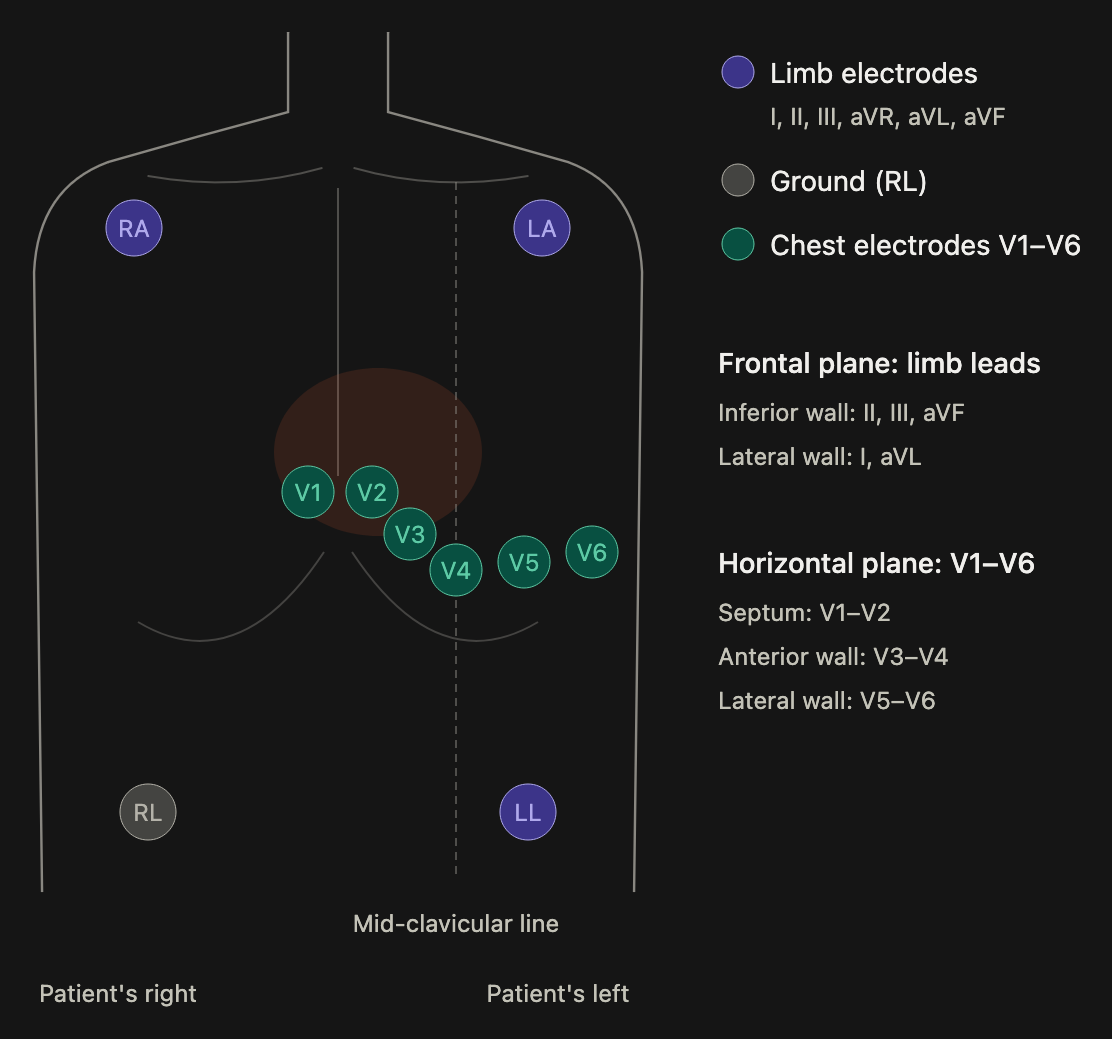

In [ ]:
wave_sample_path = os.path.join(PATH, "records100/00000/00001_lr")
record = wfdb.rdrecord(wave_sample_path)

print(f"Sampling frequency: {record.fs} Hz")
print(f"Channel names: {record.sig_name}")
print(f"Units {record.units}")
print(f"Shape: {record.p_signal.shape}")

In [ ]:
# plot a wave
plt.plot(record.p_signal[:, 0])
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title("ECG Signal")
plt.show()

In [ ]:
wfdb.plot_wfdb(record=record, figsize=(12, 14), ecg_grids="all")